In [90]:
from __future__ import annotations

import copy
import csv
import json
import math
import os
import random
import time
from dataclasses import asdict, dataclass
from pathlib import Path
from typing import Optional

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torchvision.datasets import CIFAR10
from torchvision.transforms import functional as TF


In [91]:
# ============================================================
# EXPERIMENT CONFIGURATION
# ============================================================

@dataclass
class ExperimentConfig:
    # -------------------------
    # AUTHOR-SPECIFIED SETTINGS
    # -------------------------
    crop_size: int = 28
    num_classes: int = 10

    momentum: float = 0.9
    inception_lr: float = 0.1
    alexnet_lr: float = 0.01
    mlp_lr: float = 0.01
    lr_decay_per_epoch: float = 0.95

    # Randomization experiments use no explicit regularization.
    weight_decay: float = 0.0

    # -------------------------
    # REPRODUCTION CHOICES
    # Not specified by the paper.
    # -------------------------
    seed: int = 12345
    batch_size: int = 128
    num_workers: int = 0

    # Paper never explicitly specifies the classification loss.
    loss_name: str = "cross_entropy"

    # Operational convergence definition:
    # first full-training evaluation at exactly 100% accuracy.
    convergence_accuracy: float = 1.0

    # Once online training accuracy is near perfect, evaluate
    # the entire training set this often.
    convergence_eval_every_steps: int = 50
    convergence_trigger_accuracy: float = 0.999

    # Diagnostic thresholds; these are NOT the primary definition.
    diagnostic_accuracy_thresholds: tuple = (0.99, 0.999, 1.0)

    # Safety budget. The paper does not specify a maximum.
    max_epochs: int = 5

    # Figure 1(a) visually extends to ~25k steps.
    # This is a reproduction run budget, NOT an author statement
    # that training terminated exactly there.
    fig1a_max_steps: int = 2_000

    # Paper does not state exact sampled corruption levels.
    corruption_levels = (0.0, 0.5, 1.0)

    # Logging frequency for ordinary minibatch logs.
    log_every_steps: int = 25

    # Our operational interpretation of "pixel".
    pixel_permutation_mode: str = "spatial_rgb_triplet"

    # Our operational Gaussian definition.
    gaussian_statistics: str = "global_train_scalar"

    # Our approximation to the paper's named
    # TensorFlow per_image_whitening preprocessing.
    whitening_std_floor: str = "1/sqrt(num_values)"

    # Saving
    output_dir: str = "./zhang_fig1_results"


CFG = ExperimentConfig()

OUTPUT_DIR = Path(CFG.output_dir)
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
RESULTS_DIR = OUTPUT_DIR / "results"
FIGURE_DIR = OUTPUT_DIR / "figures"

for p in (OUTPUT_DIR, CHECKPOINT_DIR, RESULTS_DIR, FIGURE_DIR):
    p.mkdir(parents=True, exist_ok=True)

print(json.dumps(asdict(CFG), indent=2))

{
  "crop_size": 28,
  "num_classes": 10,
  "momentum": 0.9,
  "inception_lr": 0.1,
  "alexnet_lr": 0.01,
  "mlp_lr": 0.01,
  "lr_decay_per_epoch": 0.95,
  "weight_decay": 0.0,
  "seed": 12345,
  "batch_size": 128,
  "num_workers": 0,
  "loss_name": "cross_entropy",
  "convergence_accuracy": 1.0,
  "convergence_eval_every_steps": 50,
  "convergence_trigger_accuracy": 0.999,
  "diagnostic_accuracy_thresholds": [
    0.99,
    0.999,
    1.0
  ],
  "max_epochs": 5,
  "fig1a_max_steps": 2000,
  "log_every_steps": 25,
  "pixel_permutation_mode": "spatial_rgb_triplet",
  "gaussian_statistics": "global_train_scalar",
  "whitening_std_floor": "1/sqrt(num_values)",
  "output_dir": "./zhang_fig1_results"
}


In [92]:
def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    # Reproducibility preference.
    # Some CUDA operations may still vary across PyTorch/platform versions.
    try:
        torch.use_deterministic_algorithms(True, warn_only=True)
    except Exception:
        pass


seed_everything(CFG.seed)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)
print("PyTorch:", torch.__version__)
print("Seed:", CFG.seed)

print("DEVICE:", DEVICE)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
PyTorch: 2.14.1+cu130
Seed: 12345
DEVICE: cuda
CUDA available: True
GPU: NVIDIA GeForce RTX 3080 Laptop GPU


In [93]:
def environment_metadata():
    return {
        "torch_version": torch.__version__,
        "cuda_available": torch.cuda.is_available(),
        "cuda_version": torch.version.cuda,
        "device": str(DEVICE),
        "config": asdict(CFG),
    }


with open(OUTPUT_DIR / "environment.json", "w") as f:
    json.dump(environment_metadata(), f, indent=2)

In [94]:
def center_crop_28(image):
    """
    AUTHOR:
        CIFAR-10 32x32 -> center crop 28x28.
        Pixel values scaled to [0,1].

    Returns:
        Tensor [3, 28, 28].
    """
    x = TF.to_tensor(image)  # reproduction implementation of /255
    x = TF.center_crop(x, [CFG.crop_size, CFG.crop_size])
    return x

In [95]:
def per_image_whiten(x: torch.Tensor) -> torch.Tensor:
    """
    Reproduction approximation to the paper's named
    TensorFlow `per_image_whitening`.

    PAPER:
        subtract mean and divide by "adjusted standard deviation"
        independently for each image.

    REPRODUCTION CHOICE:
        adjusted_std = max(population_std, 1/sqrt(num_values))

    This formula is OUR operational definition for this reproduction.
    It is not stated mathematically in Zhang et al.
    """
    mean = x.mean()

    # Population standard deviation.
    std = x.std(unbiased=False)

    floor = 1.0 / math.sqrt(x.numel())
    adjusted_std = max(float(std), floor)

    return (x - mean) / adjusted_std

In [96]:
class PaperCIFAR10(Dataset):
    def __init__(
        self,
        root: str,
        train: bool,
        download: bool = True,
        whiten: bool = True,
    ):
        self.base = CIFAR10(
            root=root,
            train=train,
            download=download,
        )
        self.whiten = whiten

    def __len__(self):
        return len(self.base)

    def __getitem__(self, index):
        image, label = self.base[index]

        x = center_crop_28(image)

        if self.whiten:
            x = per_image_whiten(x)

        return x, label

In [97]:
DATA_ROOT = "./data"

train_base = PaperCIFAR10(DATA_ROOT, train=True, download=True)
test_base = PaperCIFAR10(DATA_ROOT, train=False, download=True)

print(len(train_base), len(test_base))
print(train_base[0][0].shape)

50000 10000
torch.Size([3, 28, 28])


In [98]:
def make_corrupted_labels(
    original_labels,
    corruption_probability: float,
    seed: int,
    num_classes: int = 10,
):
    """
    Fixed partial corruption.

    For each example independently:
      with probability p -> replace by Uniform({0,...,9})

    The replacement CAN equal the original label.
    """
    labels = np.asarray(original_labels, dtype=np.int64).copy()

    rng = np.random.default_rng(seed)

    mask = rng.random(len(labels)) < corruption_probability
    replacements = rng.integers(
        low=0,
        high=num_classes,
        size=len(labels),
        dtype=np.int64,
    )

    labels[mask] = replacements[mask]

    return labels, mask

In [99]:
class FixedLabelDataset(Dataset):
    def __init__(self, dataset: Dataset, labels):
        assert len(dataset) == len(labels)
        self.dataset = dataset
        self.labels = np.asarray(labels, dtype=np.int64)

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, index):
        x, _ = self.dataset[index]
        return x, int(self.labels[index])

In [100]:
def cifar_labels(train=True):
    ds = CIFAR10(DATA_ROOT, train=train, download=True)
    return np.asarray(ds.targets, dtype=np.int64)

In [101]:
class ShuffledPixelsDataset(Dataset):
    """
    PAPER:
        one random pixel permutation, applied to all images.

    REPRODUCTION CHOICE:
        permutation is over the 28x28 spatial locations;
        RGB channels move together.

        Transformation order:
            scale -> crop -> permute -> whiten
    """

    def __init__(self, root, train, permutation, download=True):
        self.base = CIFAR10(root, train=train, download=download)
        self.permutation = torch.as_tensor(permutation, dtype=torch.long)

    def __len__(self):
        return len(self.base)

    def __getitem__(self, index):
        image, label = self.base[index]

        x = center_crop_28(image)

        c, h, w = x.shape
        flat = x.reshape(c, h * w)
        flat = flat[:, self.permutation]
        x = flat.reshape(c, h, w)

        x = per_image_whiten(x)

        return x, label

In [102]:
rng = np.random.default_rng(CFG.seed + 100)
SHARED_PIXEL_PERMUTATION = rng.permutation(CFG.crop_size * CFG.crop_size)

In [103]:
def compute_global_cropped_train_stats(root="./data"):
    """
    REPRODUCTION CHOICE:
        Match one scalar mean and variance across all channels/pixels
        of the cropped [0,1] CIFAR-10 training set.
    """
    ds = CIFAR10(root, train=True, download=True)

    total = 0.0
    total_sq = 0.0
    count = 0

    for image, _ in ds:
        x = center_crop_28(image).double()

        total += x.sum().item()
        total_sq += (x * x).sum().item()
        count += x.numel()

    mean = total / count
    variance = total_sq / count - mean ** 2
    std = math.sqrt(max(variance, 0.0))

    return mean, std

In [104]:
GAUSSIAN_MEAN, GAUSSIAN_STD = compute_global_cropped_train_stats(DATA_ROOT)

print("Gaussian matching mean:", GAUSSIAN_MEAN)
print("Gaussian matching std :", GAUSSIAN_STD)

Gaussian matching mean: 0.4677336776348152
Gaussian matching std : 0.24710995575604078


In [105]:
class GaussianInputDataset(Dataset):
    """
    PAPER:
        Gaussian random pixels with mean/variance matching
        the original image dataset.

    REPRODUCTION CHOICES:
        - global scalar mean/std
        - statistics calculated after /255 and center crop
        - Gaussian image fixed for each example across epochs
        - generated Gaussian image is then per-image whitened
    """

    def __init__(
        self,
        root,
        train,
        seed,
        mean,
        std,
        download=True,
    ):
        self.base = CIFAR10(root, train=train, download=download)
        self.seed = seed
        self.mean = mean
        self.std = std

    def __len__(self):
        return len(self.base)

    def __getitem__(self, index):
        _, label = self.base[index]

        generator = torch.Generator()
        generator.manual_seed(self.seed + index)

        x = torch.randn(
            3,
            CFG.crop_size,
            CFG.crop_size,
            generator=generator,
        )

        x = x * self.std + self.mean
        x = per_image_whiten(x)

        return x, label

In [106]:
class RandomPixelsDataset(Dataset):
    """
    Random-pixel condition for Figure 1(a).

    REPRODUCTION CHOICES:
        - replace each CIFAR-10 image with independent uniform
          random pixels in [0, 1]
        - random image is fixed for each example across epochs
        - retain the original CIFAR-10 label
        - generate at the paper's 28x28 cropped resolution
        - apply the same per-image whitening preprocessing
    """

    def __init__(
        self,
        root,
        train,
        seed,
        download=True,
    ):
        self.base = CIFAR10(
            root,
            train=train,
            download=download,
        )
        self.seed = seed

    def __len__(self):
        return len(self.base)

    def __getitem__(self, index):
        # Keep the original CIFAR-10 label
        _, label = self.base[index]

        # Deterministic random image for this particular example.
        # This ensures the random image does NOT change each epoch.
        generator = torch.Generator()
        generator.manual_seed(self.seed + index)

        # Independent uniform random pixels in [0, 1]
        x = torch.rand(
            3,
            CFG.crop_size,
            CFG.crop_size,
            generator=generator,
        )

        # Match preprocessing used elsewhere in the notebook
        x = per_image_whiten(x)

        return x, label

In [107]:
class MLP1x512(nn.Module):
    def __init__(self):
        super().__init__()

        input_dim = 28 * 28 * 3

        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(input_dim, 512),
            nn.ReLU(inplace=True),
            nn.Linear(512, 10),
        )

    def forward(self, x):
        return self.net(x)

In [108]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


mlp = MLP1x512()

print("MLP parameters:", count_parameters(mlp))
print("Paper Table 1 :", 1_209_866)

assert count_parameters(mlp) == 1_209_866

MLP parameters: 1209866
Paper Table 1 : 1209866


In [109]:
class SmallAlexNet(nn.Module):
    """
    PAPER:
        [conv5x5 -> maxpool3x3 -> LRN] x 2
        FC 384 -> FC 192 -> FC 10
        ReLU activations.

    REPRODUCTION INFERENCE:
        64 channels in both conv layers,
        conv stride=1, padding=2,
        pool stride=2, padding=1.

    These choices reproduce Table 1's exact parameter count.

    LRN parameters are reproduction choices because the paper
    does not specify them.
    """

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=5, stride=1, padding=2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1),
            nn.LocalResponseNorm(
                size=5,
                alpha=1e-4,
                beta=0.75,
                k=1.0,
            ),

            nn.Conv2d(64, 64, kernel_size=5, stride=1, padding=2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1),
            nn.LocalResponseNorm(
                size=5,
                alpha=1e-4,
                beta=0.75,
                k=1.0,
            ),
        )

        # 28 -> 14 -> 7
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 384),
            nn.ReLU(inplace=True),
            nn.Linear(384, 192),
            nn.ReLU(inplace=True),
            nn.Linear(192, 10),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

In [110]:
alexnet = SmallAlexNet()

print("AlexNet parameters:", count_parameters(alexnet))
print("Paper Table 1    :", 1_387_786)

assert count_parameters(alexnet) == 1_387_786

AlexNet parameters: 1387786
Paper Table 1    : 1387786


In [111]:
class ConvModule(nn.Module):
    def __init__(
        self,
        in_channels,
        out_channels,
        kernel_size,
        stride=1,
    ):
        super().__init__()

        # REPRODUCTION CHOICE:
        # "same"-style padding for odd kernels.
        padding = kernel_size // 2

        self.net = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=kernel_size,
                stride=stride,
                padding=padding,
                bias=True,
            ),

            # Figure 3 explicitly includes BN.
            #
            # affine=False is our inference from Table 1's
            # reported parameter count.
            nn.BatchNorm2d(
                out_channels,
                affine=False,
            ),

            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.net(x)

In [112]:
class InceptionModule(nn.Module):
    def __init__(self, in_channels, ch1, ch3):
        super().__init__()

        self.branch1 = ConvModule(
            in_channels,
            ch1,
            kernel_size=1,
            stride=1,
        )

        self.branch3 = ConvModule(
            in_channels,
            ch3,
            kernel_size=3,
            stride=1,
        )

    def forward(self, x):
        return torch.cat(
            [self.branch1(x), self.branch3(x)],
            dim=1,
        )

In [113]:
class DownsampleModule(nn.Module):
    def __init__(self, in_channels, ch3):
        super().__init__()

        self.conv = ConvModule(
            in_channels,
            ch3,
            kernel_size=3,
            stride=2,
        )

        # REPRODUCTION CHOICE:
        # padding=1 makes 28 -> 14 and 14 -> 7,
        # matching the final 7x7 global pooling shown in Figure 3.
        self.pool = nn.MaxPool2d(
            kernel_size=3,
            stride=2,
            padding=1,
        )

    def forward(self, x):
        return torch.cat(
            [self.conv(x), self.pool(x)],
            dim=1,
        )

In [114]:
class SmallInception(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            # 28x28
            ConvModule(3, 96, 3),

            InceptionModule(96, 32, 32),       # -> 64
            InceptionModule(64, 32, 48),       # -> 80

            DownsampleModule(80, 80),          # -> 160, 14x14

            InceptionModule(160, 112, 48),     # -> 160
            InceptionModule(160, 96, 64),      # -> 160
            InceptionModule(160, 80, 80),      # -> 160
            InceptionModule(160, 48, 96),      # -> 144

            DownsampleModule(144, 96),         # -> 240, 7x7

            InceptionModule(240, 176, 160),    # -> 336
            InceptionModule(336, 176, 160),    # -> 336
        )

        # Figure 3: 7x7 global mean pooling.
        self.pool = nn.AvgPool2d(kernel_size=7)

        self.fc = nn.Linear(336, 10)

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        return self.fc(x)

In [115]:
inception = SmallInception()

print("Inception parameters:", count_parameters(inception))
print("Paper Table 1       :", 1_649_402)

assert count_parameters(inception) == 1_649_402

Inception parameters: 1649402
Paper Table 1       : 1649402


In [116]:
def build_model(name: str):
    name = name.lower()

    if name == "inception":
        return SmallInception()

    if name == "alexnet":
        return SmallAlexNet()

    if name in ("mlp", "mlp1x512"):
        return MLP1x512()

    raise ValueError(f"Unknown model: {name}")

In [117]:
def initial_lr_for_model(name):
    name = name.lower()

    if name == "inception":
        return CFG.inception_lr

    if name == "alexnet":
        return CFG.alexnet_lr

    if name in ("mlp", "mlp1x512"):
        return CFG.mlp_lr

    raise ValueError(name)

In [118]:
def build_training_objects(model, model_name):
    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=initial_lr_for_model(model_name),
        momentum=CFG.momentum,
        weight_decay=CFG.weight_decay,

        # REPRODUCTION CHOICE:
        nesterov=False,
    )

    scheduler = torch.optim.lr_scheduler.ExponentialLR(
        optimizer,
        gamma=CFG.lr_decay_per_epoch,
    )

    return criterion, optimizer, scheduler

In [119]:
def make_loader(
    dataset,
    train: bool,
    batch_size=None,
):
    if batch_size is None:
        batch_size = CFG.batch_size

    generator = torch.Generator()
    generator.manual_seed(CFG.seed)

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=train,
        num_workers=CFG.num_workers,
        pin_memory=torch.cuda.is_available(),
        generator=generator if train else None,
    )

In [120]:
@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)

        logits = model(x)
        loss = criterion(logits, y)

        batch_size = y.size(0)

        total_loss += loss.item() * batch_size
        total_correct += (logits.argmax(dim=1) == y).sum().item()
        total_examples += batch_size

    return {
        "loss": total_loss / total_examples,
        "accuracy": total_correct / total_examples,
        "error": 1.0 - total_correct / total_examples,
        "n": total_examples,
    }

In [121]:
def save_json(obj, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)

    with open(path, "w") as f:
        json.dump(obj, f, indent=2)


def save_checkpoint(
    path,
    model,
    optimizer,
    scheduler,
    epoch,
    global_step,
    metadata,
):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)

    torch.save(
        {
            "model_state": model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "scheduler_state": scheduler.state_dict(),
            "epoch": epoch,
            "global_step": global_step,
            "metadata": metadata,
        },
        path,
    )

In [122]:
def write_log_csv(log_records, path):
    if not log_records:
        return

    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)

    keys = sorted(
        set().union(*(record.keys() for record in log_records))
    )

    with open(path, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=keys)
        writer.writeheader()
        writer.writerows(log_records)

In [123]:
def train_experiment(
    *,
    model_name,
    train_dataset,
    test_dataset=None,
    experiment_name,
    max_epochs=None,
    max_steps=None,
    stop_at_convergence=True,
):
    seed_everything(CFG.seed)

    if max_epochs is None:
        max_epochs = CFG.max_epochs

    model = build_model(model_name).to(DEVICE)
    criterion, optimizer, scheduler = build_training_objects(
        model,
        model_name,
    )

    train_loader = make_loader(train_dataset, train=True)

    # Full fixed-dataset evaluation loader.
    train_eval_loader = make_loader(train_dataset, train=False)

    test_loader = (
        make_loader(test_dataset, train=False)
        if test_dataset is not None
        else None
    )

    logs = []
    full_eval_logs = []

    global_step = 0
    convergence_step = None

    threshold_steps = {
        str(t): None
        for t in CFG.diagnostic_accuracy_thresholds
    }

    near_convergence = False

    run_start = time.time()

    for epoch in range(max_epochs):
        model.train()

        epoch_correct = 0
        epoch_seen = 0
        epoch_loss_sum = 0.0

        for batch_idx, (x, y) in enumerate(train_loader):
            x = x.to(DEVICE, non_blocking=True)
            y = y.to(DEVICE, non_blocking=True)

            if batch_idx == 0 and epoch ==0:
                print("Model device:", next(model.parameters()).device)
                print("Input device:", x.device)
                print("Target device:", y.device)
                print("GPU memory allocated:", round(torch.cuda.memory_allocated() / 1024**2, 1), "MB" )
            optimizer.zero_grad(set_to_none=True)

            logits = model(x)
            loss = criterion(logits, y)

            if not torch.isfinite(loss):
                print(
                    f"\nWARNING: Non-finite loss at step {global_step}: "
                    f"{loss.item()}"
                )
                print("Stopping this experiment.")
                break

            loss.backward()
            optimizer.step()

            if global_step % 100 == 0:
                print(
                    f"Step {global_step}/{max_steps} | "
                    f"Loss: {loss.item():.4f}"
                )

            global_step += 1

            with torch.no_grad():
                predictions = logits.argmax(dim=1)
                correct = (predictions == y).sum().item()

            batch_n = y.size(0)

            epoch_correct += correct
            epoch_seen += batch_n
            epoch_loss_sum += loss.item() * batch_n

            running_accuracy = epoch_correct / epoch_seen
            running_loss = epoch_loss_sum / epoch_seen

            if global_step % CFG.log_every_steps == 0:
                logs.append(
                    {
                        "step": global_step,
                        "epoch": epoch,
                        "batch": batch_idx,
                        "train_batch_loss": loss.item(),
                        "train_epoch_running_loss": running_loss,
                        "train_epoch_running_accuracy": running_accuracy,
                        "lr": optimizer.param_groups[0]["lr"],
                        "elapsed_seconds": time.time() - run_start,
                    }
                )

            # Trigger expensive full-training evaluation only when
            # the online accuracy indicates we're close.
            if running_accuracy >= CFG.convergence_trigger_accuracy:
                near_convergence = True

            should_full_eval = (
                near_convergence
                and global_step % CFG.convergence_eval_every_steps == 0
            )

            if should_full_eval:
                train_metrics = evaluate(
                    model,
                    train_eval_loader,
                    criterion,
                )

                full_eval_logs.append(
                    {
                        "step": global_step,
                        "epoch": epoch,
                        "train_full_loss": train_metrics["loss"],
                        "train_full_accuracy": train_metrics["accuracy"],
                    }
                )

                for threshold in CFG.diagnostic_accuracy_thresholds:
                    key = str(threshold)

                    if (
                        threshold_steps[key] is None
                        and train_metrics["accuracy"] >= threshold
                    ):
                        threshold_steps[key] = global_step

                if (
                    convergence_step is None
                    and train_metrics["accuracy"]
                    >= CFG.convergence_accuracy
                ):
                    convergence_step = global_step

                    save_checkpoint(
                        CHECKPOINT_DIR
                        / f"{experiment_name}_converged.pt",
                        model,
                        optimizer,
                        scheduler,
                        epoch,
                        global_step,
                        metadata={
                            "experiment_name": experiment_name,
                            "model_name": model_name,
                            "convergence_definition":
                                "first full-training evaluation "
                                "with accuracy == 1.0",
                        },
                    )

                    if stop_at_convergence:
                        break

            if max_steps is not None and global_step >= max_steps:
                break

        # AUTHOR: LR multiplied by 0.95 once per epoch.
        scheduler.step()

        # Always do a full evaluation at the end of every epoch.
        train_metrics = evaluate(
            model,
            train_eval_loader,
            criterion,
        )

        full_eval_logs.append(
            {
                "step": global_step,
                "epoch": epoch,
                "train_full_loss": train_metrics["loss"],
                "train_full_accuracy": train_metrics["accuracy"],
            }
        )

        for threshold in CFG.diagnostic_accuracy_thresholds:
            key = str(threshold)

            if (
                threshold_steps[key] is None
                and train_metrics["accuracy"] >= threshold
            ):
                threshold_steps[key] = global_step

        if (
            convergence_step is None
            and train_metrics["accuracy"]
            >= CFG.convergence_accuracy
        ):
            convergence_step = global_step

            save_checkpoint(
                CHECKPOINT_DIR
                / f"{experiment_name}_converged.pt",
                model,
                optimizer,
                scheduler,
                epoch,
                global_step,
                metadata={
                    "experiment_name": experiment_name,
                    "model_name": model_name,
                },
            )

        if stop_at_convergence and convergence_step is not None:
            break

        if max_steps is not None and global_step >= max_steps:
            break

    final_train = evaluate(
        model,
        train_eval_loader,
        criterion,
    )

    final_test = (
        evaluate(model, test_loader, criterion)
        if test_loader is not None
        else None
    )

    result = {
        "experiment_name": experiment_name,
        "model_name": model_name,
        "global_steps": global_step,
        "epochs_completed": epoch + 1,
        "convergence_step": convergence_step,
        "convergence_eval_resolution_steps":
            CFG.convergence_eval_every_steps,
        "threshold_steps": threshold_steps,
        "final_train": final_train,
        "final_test": final_test,
        "config": asdict(CFG),
    }

    write_log_csv(
        logs,
        RESULTS_DIR / f"{experiment_name}_training.csv",
    )

    write_log_csv(
        full_eval_logs,
        RESULTS_DIR / f"{experiment_name}_full_eval.csv",
    )

    save_json(
        result,
        RESULTS_DIR / f"{experiment_name}_summary.json",
    )

    save_checkpoint(
        CHECKPOINT_DIR / f"{experiment_name}_final.pt",
        model,
        optimizer,
        scheduler,
        epoch,
        global_step,
        metadata=result,
    )

    return result

In [124]:
def build_fig1a_dataset(condition: str, train: bool):
    condition = condition.lower()

    if condition == "true_labels":
        return PaperCIFAR10(
            DATA_ROOT,
            train=train,
            download=True,
        )

    if condition == "random_labels":
        base = PaperCIFAR10(
            DATA_ROOT,
            train=train,
            download=True,
        )

        # Figure 1(a)'s random-label condition is meaningful
        # primarily for training.
        original = cifar_labels(train=train)

        labels, _ = make_corrupted_labels(
            original,
            corruption_probability=1.0,
            seed=CFG.seed + (1000 if train else 2000),
        )

        return FixedLabelDataset(base, labels)

    if condition == "shuffled_pixels":
        return ShuffledPixelsDataset(
            DATA_ROOT,
            train=train,
            permutation=SHARED_PIXEL_PERMUTATION,
        )

    if condition == "random_pixels":
        return RandomPixelsDataset(
            DATA_ROOT,
            train=train,
            seed=CFG.seed + (3000 if train else 4000),
        )

    if condition == "gaussian":
        return GaussianInputDataset(
            DATA_ROOT,
            train=train,
            seed=CFG.seed + (5000 if train else 6000),
            mean=GAUSSIAN_MEAN,
            std=GAUSSIAN_STD,
        )

    raise ValueError(condition)

In [125]:
FIG1A_CONDITIONS = [
    "true_labels",
    "random_labels",
    "shuffled_pixels",
    "random_pixels",
    "gaussian",
]

In [126]:
def run_figure_1a():
    summaries = {}

    for condition in FIG1A_CONDITIONS:
        experiment_name = f"fig1a_inception_{condition}"

        summary_path = (
            RESULTS_DIR / f"{experiment_name}_summary.json"
        )

        if summary_path.exists():
            print("Already exists; skipping:", experiment_name)

            with open(summary_path) as f:
                summaries[condition] = json.load(f)

            continue

        print("\nRunning:", experiment_name)

        train_dataset = build_fig1a_dataset(
            condition,
            train=True,
        )

        result = train_experiment(
            model_name="inception",
            train_dataset=train_dataset,
            test_dataset=None,
            experiment_name=experiment_name,
            max_steps=CFG.fig1a_max_steps,
            stop_at_convergence=False,
        )

        summaries[condition] = result

    return summaries

In [127]:
def build_partial_corruption_dataset(p: float):
    base = PaperCIFAR10(
        DATA_ROOT,
        train=True,
        download=True,
    )

    original_labels = cifar_labels(train=True)

    # Deterministic seed tied to p.
    corruption_seed = CFG.seed + 10_000 + int(round(p * 10_000))

    corrupted_labels, mask = make_corrupted_labels(
        original_labels,
        corruption_probability=p,
        seed=corruption_seed,
    )

    dataset = FixedLabelDataset(
        base,
        corrupted_labels,
    )

    metadata = {
        "p": float(p),
        "corruption_seed": corruption_seed,
        "selected_for_corruption": int(mask.sum()),
        "selected_fraction": float(mask.mean()),
        "actually_changed_labels": int(
            np.sum(corrupted_labels != original_labels)
        ),
        "actually_changed_fraction": float(
            np.mean(corrupted_labels != original_labels)
        ),
    }

    return dataset, metadata

In [128]:
FIG1BC_MODELS = [
    "inception",
    "alexnet",
    "mlp1x512",
]

In [129]:
def run_corruption_sweep():
    test_dataset = PaperCIFAR10(
        DATA_ROOT,
        train=False,
        download=True,
    )

    all_results = {}

    for model_name in FIG1BC_MODELS:
        all_results[model_name] = {}

        for p in CFG.corruption_levels:
            p = float(p)

            experiment_name = (
                f"fig1bc_{model_name}_p{p:.1f}"
            )

            summary_path = (
                RESULTS_DIR
                / f"{experiment_name}_summary.json"
            )

            if summary_path.exists():
                print("Already exists; skipping:", experiment_name)

                with open(summary_path) as f:
                    all_results[model_name][p] = json.load(f)

                continue

            train_dataset, corruption_metadata = (
                build_partial_corruption_dataset(p)
            )

            save_json(
                corruption_metadata,
                RESULTS_DIR
                / f"{experiment_name}_corruption.json",
            )

            print(
                f"\nRunning {model_name}, "
                f"label corruption p={p:.1f}"
            )

            result = train_experiment(
                model_name=model_name,
                train_dataset=train_dataset,
                test_dataset=test_dataset,
                experiment_name=experiment_name,
                max_epochs=CFG.max_epochs,

                # Figure 1(b/c) concern convergence.
                stop_at_convergence=True,
            )

            result["corruption"] = corruption_metadata

            save_json(
                result,
                summary_path,
            )

            all_results[model_name][p] = result

    return all_results

In [148]:
def calculate_relative_convergence(results):
    relative = {}

    for model_name, model_results in results.items():

        baseline = model_results[0.0]

        # Use actual convergence step when available.
        # Otherwise use the final step reached under our reduced
        # computational budget.
        t0 = baseline["convergence_step"]

        if t0 is None:
            t0 = baseline["global_steps"]
            print(
                f"WARNING: {model_name} did not converge at p=0. "
                f"Using capped training step {t0}."
            )

        relative[model_name] = {}

        for p, result in model_results.items():

            tp = result["convergence_step"]

            if tp is None:
                tp = result["global_steps"]
                print(
                    f"WARNING: {model_name}, p={p} did not converge. "
                    f"Using capped training step {tp}."
                )

            relative[model_name][p] = tp / t0

    return relative

In [131]:
def collect_test_errors(results):
    test_errors = {}

    for model_name, model_results in results.items():
        test_errors[model_name] = {}

        for p, result in model_results.items():

            # Do not treat a non-converged run as an
            # "after convergence" Figure 1(c) point.
            if result["convergence_step"] is None:
                test_errors[model_name][p] = None
                continue

            test_errors[model_name][p] = (
                result["final_test"]["error"]
            )

    return test_errors

In [132]:
def load_json(path):
    with open(path) as f:
        return json.load(f)

In [133]:
def load_fig1bc_results():
    results = {}

    for model_name in FIG1BC_MODELS:
        results[model_name] = {}

        for p in CFG.corruption_levels:
            p = float(p)

            experiment_name = (
                f"fig1bc_{model_name}_p{p:.1f}"
            )

            path = (
                RESULTS_DIR
                / f"{experiment_name}_summary.json"
            )

            if not path.exists():
                print("Missing:", path)
                continue

            results[model_name][p] = load_json(path)

    return results

In [134]:
def read_csv_numeric(path):
    rows = []

    with open(path) as f:
        reader = csv.DictReader(f)

        for row in reader:
            converted = {}

            for k, v in row.items():
                try:
                    converted[k] = float(v)
                except (ValueError, TypeError):
                    converted[k] = v

            rows.append(converted)

    return rows

In [135]:
def plot_figure_1a():
    plt.figure(figsize=(7, 5))

    for condition in FIG1A_CONDITIONS:
        path = (
            RESULTS_DIR
            / f"fig1a_inception_{condition}_training.csv"
        )

        if not path.exists():
            print("Missing:", path)
            continue

        rows = read_csv_numeric(path)

        steps = np.array([r["step"] for r in rows])
        losses = np.array(
            [r["train_epoch_running_loss"] for r in rows]
        )

        plt.plot(
            steps / 1000.0,
            losses,
            label=condition.replace("_", " "),
        )

    plt.xlabel("thousand steps")
    plt.ylabel("training loss")
    plt.title("Figure 1(a) reproduction")
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR / "figure_1a_reproduction.png",
        dpi=200,
    )

    plt.show()

In [157]:
def plot_figure_1b(results):
    relative = calculate_relative_convergence(results)

    plt.figure(figsize=(7, 5))

    for model_name in FIG1BC_MODELS:
        ps = sorted(relative[model_name].keys())

        valid = [
            p for p in ps
            if relative[model_name][p] is not None
        ]

        ys = [
            relative[model_name][p]
            for p in valid
        ]

        plt.plot(
            valid,
            ys,
            marker="o",
            label=model_name,
        )

    plt.xlabel("label corruption")
    plt.ylabel("relative convergence time T(p) / T(0)")
    plt.title("Figure 1(b) reproduction")
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR / "figure_1b_reproduction.png",
        dpi=200,
    )

    plt.show()

In [165]:
def plot_figure_1c(results):
    fig, ax = plt.subplots(figsize=(8, 5))

    for model_name in ["inception", "alexnet", "mlp1x512"]:

        if model_name not in results:
            print(f"Skipping missing model: {model_name}")
            continue

        model_results = results[model_name]

        # Use the corruption levels that actually exist
        ps = sorted(model_results.keys())

        train_errors = []
        test_errors = []

        for p in ps:
            train_error = model_results[p]["final_train"]["error"]
            test_error = model_results[p]["final_test"]["error"]

            train_errors.append(train_error)
            test_errors.append(test_error)

        print(model_name)
        print("  p:", ps)
        print("  train:", train_errors)
        print("  test:", test_errors)

        ax.plot(
            ps,
            train_errors,
            marker="o",
            linestyle="--",
            linewidth=2,
            markersize=7,
            label=f"{model_name} train",
        )

        ax.plot(
            ps,
            test_errors,
            marker="o",
            linestyle="-",
            linewidth=2,
            markersize=7,
            label=f"{model_name} test",
        )

    ax.set_xlabel("Label corruption probability p")
    ax.set_ylabel("Error")
    ax.set_title("Figure 1(c): Error vs. label corruption")

    ax.set_xlim(-0.05, 1.05)
    ax.set_ylim(0.0, 1.0)

    # Our reduced corruption grid
    ax.set_xticks([0.0, 0.5, 1.0])

    ax.grid(True, alpha=0.3)
    ax.legend()

    fig.tight_layout()
    plt.show()

    return fig

In [138]:
print(CFG)

ExperimentConfig(crop_size=28, num_classes=10, momentum=0.9, inception_lr=0.1, alexnet_lr=0.01, mlp_lr=0.01, lr_decay_per_epoch=0.95, weight_decay=0.0, seed=12345, batch_size=128, num_workers=0, loss_name='cross_entropy', convergence_accuracy=1.0, convergence_eval_every_steps=50, convergence_trigger_accuracy=0.999, diagnostic_accuracy_thresholds=(0.99, 0.999, 1.0), max_epochs=5, fig1a_max_steps=2000, log_every_steps=25, pixel_permutation_mode='spatial_rgb_triplet', gaussian_statistics='global_train_scalar', whitening_std_floor='1/sqrt(num_values)', output_dir='./zhang_fig1_results')


In [ ]:
fig1a_results = run_figure_1a()
fig1bc_results = run_corruption_sweep()

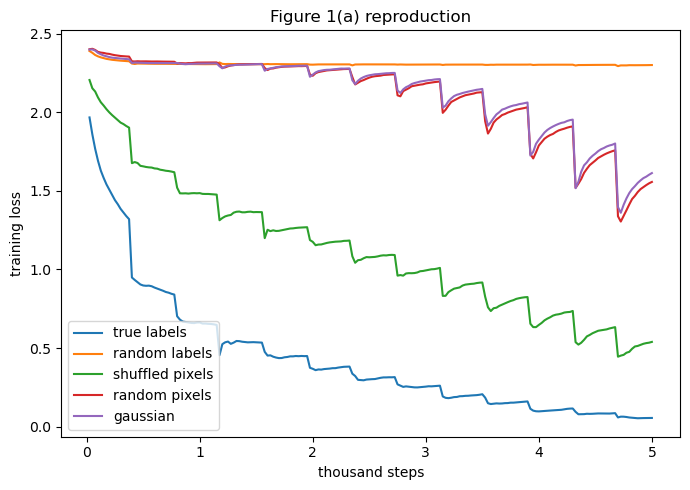

In [171]:
plot_figure_1a()

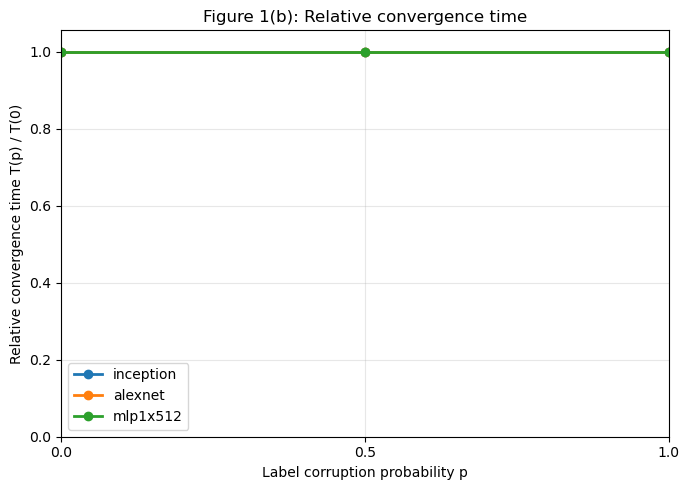

In [172]:
plot_figure_1b(fig1bc_results)

inception
  p: [0.0, 0.5, 1.0]
  train: [0.1402, 0.63556, 0.90078]
  test: [0.19430000000000003, 0.40390000000000004, 0.9105]
alexnet
  p: [0.0, 0.5, 1.0]
  train: [0.17428, 0.61554, 0.88426]
  test: [0.2589, 0.39059999999999995, 0.8976]
mlp1x512
  p: [0.0, 0.5, 1.0]
  train: [0.34946, 0.62934, 0.7672]
  test: [0.488, 0.5887, 0.9033]


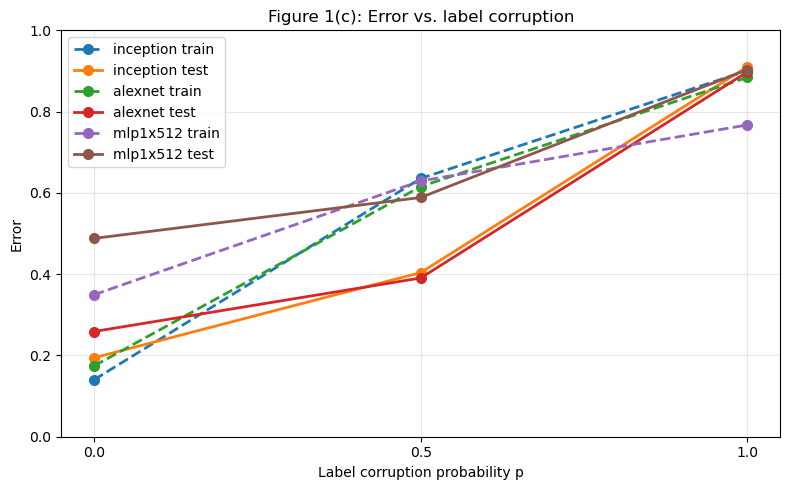

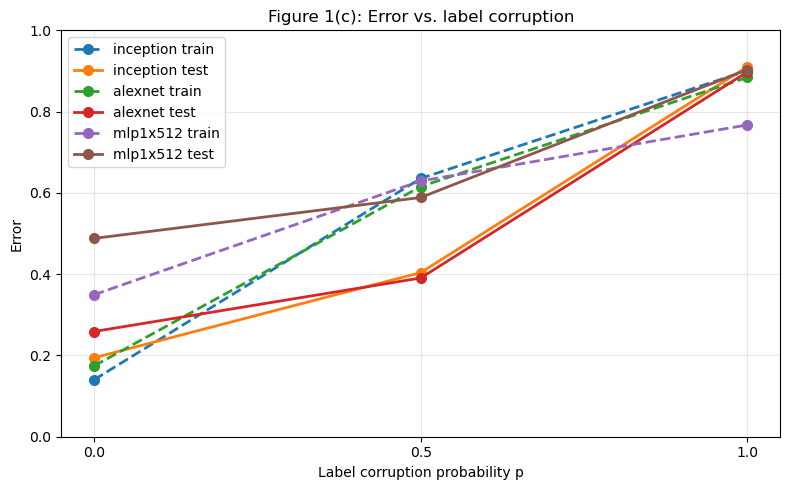

In [173]:
plot_figure_1c(fig1bc_results)